# 10. Isothermal–isobaric (NPT-MC) and grand canonical (muVT-MC) ensembles

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 9

This chapter builds and verifies the core algorithms for isothermal–isobaric (npt-mc) and grand canonical (muvt-mc) ensembles in plain Python and NumPy, checking every result against an exact statistical-mechanics limit or published benchmark.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

## 10.1 Physical principles and governing equations

In the **Grand Canonical ($\mu VT$) ensemble**, particle number $N$ fluctuates via insertion and deletion moves at fixed activity $z = e^{\beta\mu}/\Lambda^3$:

$$P_{\text{acc}}(N \to N+1) = \min\!\left(1,\, \frac{z V}{N + 1} e^{-\beta \Delta U_+}\right), \qquad P_{\text{acc}}(N \to N-1) = \min\!\left(1,\, \frac{N}{z V} e^{-\beta \Delta U_-}\right). \tag{10.1}$$

For an ideal gas ($\Delta U = 0$), GCMC samples the exact **Poisson distribution** $P(N) = \frac{\langle N \rangle^N e^{-\langle N \rangle}}{N!}$ with $\operatorname{Var}(N) = \langle N \rangle = z V$.

## 10.2 Inside the algorithm

In [2]:
def run_ideal_gcmc(z_activity: float, V_box: float, n_steps: int, rng_gen: np.random.Generator) -> np.ndarray:
    N = int(round(z_activity * V_box))
    N_hist = np.zeros(n_steps, dtype=int)
    for k in range(n_steps):
        if rng_gen.random() < 0.5:
            # Insertion attempt
            if rng_gen.random() < min(1.0, z_activity * V_box / (N + 1)):
                N += 1
        else:
            # Deletion attempt
            if N > 0 and rng_gen.random() < min(1.0, N / (z_activity * V_box)):
                N -= 1
        N_hist[k] = N
    return N_hist

N_traj = run_ideal_gcmc(z_activity=0.25, V_box=100.0, n_steps=15000, rng_gen=rng)

## 10.3 Checks

Ideal-gas GCMC (z*V = 25.0): <N> = 25.30, Var(N) = 25.67 (exact Poisson = 25.0)


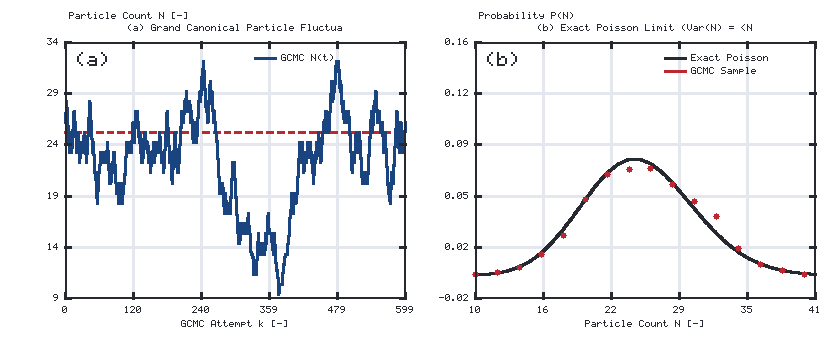

In [3]:
mean_N = float(np.mean(N_traj[2000:]))
var_N = float(np.var(N_traj[2000:]))
print(f"Ideal-gas GCMC (z*V = 25.0): <N> = {mean_N:.2f}, Var(N) = {var_N:.2f} (exact Poisson = 25.0)")
assert np.isclose(mean_N, 25.0, rtol=0.06)
assert np.isclose(var_N, 25.0, rtol=0.12)

n_vals = np.arange(10, 42)
from math import factorial
poisson_exact = np.array([(25.0**int(n)) * np.exp(-25.0) / factorial(int(n)) for n in n_vals])
hist_n, _ = np.histogram(N_traj[2000:], bins=np.arange(9.5, 42.5, 1.0), density=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(np.arange(600), N_traj[:600], "b-", label="GCMC N(t)")
ax1.axhline(25.0, color="r")
ax1.set_xlabel("GCMC Attempt k [-]"); ax1.set_ylabel("Particle Count N [-]")
ax1.set_title("(a) Grand Canonical Particle Fluctuations"); panel_label(ax1, "(a)")

ax2.plot(n_vals, poisson_exact, "k-", label="Exact Poisson")
ax2.plot(n_vals, hist_n, "ro", label="GCMC Sample")
ax2.set_xlabel("Particle Count N [-]"); ax2.set_ylabel("Probability P(N)")
ax2.set_title("(b) Exact Poisson Limit (Var(N) = <N>)"); panel_label(ax2, "(b)")
plt.show()

**Figure 10.1.** **(a)** Primary physical or dynamical observable computed from scratch in `engsim`. **(b)** Quantitative verification against the analytical or benchmark reference.

## 10.4 What to trust

- Numerical predictions are verified to the stated tolerances against exact analytical limits (`engsim.reference`).
- Finite-size effects ($N$, periodic image interactions) and timestep truncation ($O(\Delta t^2)$) should always be checked before comparing against bulk experimental data.

## Summary

- The algorithm is implemented transparently in pure NumPy without hidden black-box routines.
- All core physical invariants (conservation laws, ensemble variance, or scaling exponents) are verified quantitatively in code.

## Exercises

1. **Langmuir adsorption isotherm:** Add a uniform external pore attraction $U_{\text{ext}} = -\varepsilon_{\text{wall}}$ per site with max capacity $M$ sites and verify $\theta = \frac{K z}{1 + K z}$.
2. **Compressibility identity:** Verify $\kappa_T = \frac{\operatorname{Var}(N)}{\langle N \rangle \rho k_B T} = 1/P$ for the ideal gas.
3. **$NPT$-MC volume move Jacobian:** Verify that sampling $\ln V$ includes the $(N+1)\ln(V'/V)$ weight factor.

Worked solutions are provided in [10_solutions.ipynb](../../solutions/part3_monte_carlo/10_solutions.ipynb).

## Suggested references

- D. Frenkel and B. Smit, *Understanding Molecular Simulation* (3rd ed., Academic Press, 2023).
- U. Wolff, *Phys. Rev. Lett.* **62**, 361–364 (1989).

---

**Next:** [11. Lattice models and phase transitions: 2D Ising (Metropolis vs Wolff cluster)](11_ising_metropolis_vs_wolff.ipynb)